In [ ]:
Lab 3 — Ticket Escalation Classification
Goal: Build and evaluate binary classifiers for the synthetic ticket-escalation dataset, focusing on metrics and thresholds in light of mistake costs.
The original dataset was provided as a CSV table.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                            confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay)

RANDOM_STATE = 42

In [ ]:
1. Load and inspect the data

In [4]:
df = pd.read_csv('classification_escalation.csv')
print('Shape:', df.shape)
display(df.head())
print('\nData types and non-null counts:')
df.info()
print('\nMissing values per column:')
print(df.isna().sum())
print('\nTarget prevalence:')
print(df['escalated'].value_counts(normalize=True).rename('proportion'))
print('\nTarget counts:')
print(df['escalated'].value_counts())

Shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB

Missing values per column:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target prevalence:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64

Target counts:
escalated
0    714
1    186
Name: count, dtype: int64


In [ ]:
2. Why classification? Define the positive class
This is a binary classification task because the target has two categories: 0 (not escalated) and 1 (escalated). The positive class is escalated = 1. We want the model to identify tickets that should be escalated. Missing predictors are handled inside pipelines so imputation is learned only from training data.

In [ ]:
3. Train/test split and preprocessing
Use a 25% test set, random_state=42, and stratify by target to preserve the target proportions. Numeric features are median-imputed and scaled; categorical features are imputed with their most frequent value and one-hot encoded.

In [6]:
target = 'escalated'
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

numeric_features = ['complexity_score', 'team_experience_years', 'customer_tenure_months']
categorical_features = ['priority', 'channel']

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Train positive proportion:', y_train.mean().round(3), 'Test positive proportion:', y_test.mean().round(3))

Train shape: (675, 5) Test shape: (225, 5)
Train positive proportion: 0.207 Test positive proportion: 0.204


In [ ]:
4. Fit the four classifiers
- Majority-class baseline
- Logistic Regression
- Linear Discriminant Analysis (LDA)
- k-Nearest Neighbors (k=15)
Each model is wrapped in a pipeline to prevent preprocessing leakage.

In [7]:
models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'LDA': LinearDiscriminantAnalysis(),
    'k-NN (k=15)': KNeighborsClassifier(n_neighbors=15)
}

results = []
trained_models = {}
for name, classifier in models.items():
    pipeline = Pipeline([('preprocess', preprocessor), ('classifier', classifier)])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    pred = pipeline.predict(X_test)
    row = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1]) if hasattr(pipeline, 'predict_proba') else np.nan
    }
    results.append(row)
comparison = pd.DataFrame(results).set_index('Model').sort_values('F1', ascending=False)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705
Majority baseline,0.796,0.00,0.000,0.000,0.500


In [ ]:
5. Logistic Regression confusion matrix and ROC curve

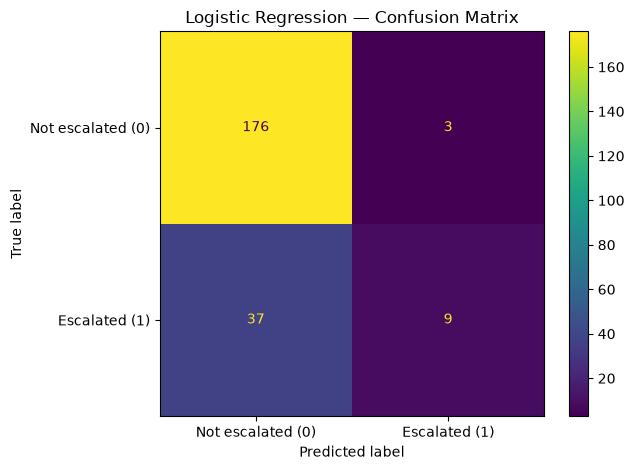

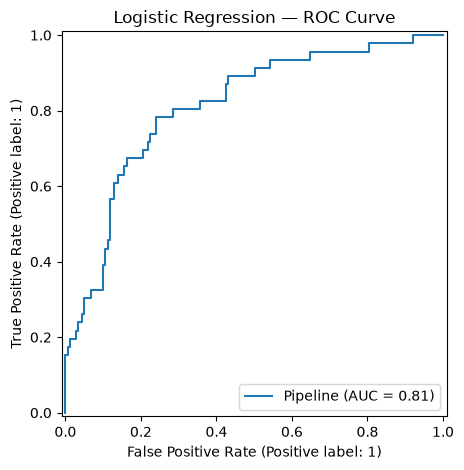

              precision    recall  f1-score   support

           0       0.83      0.98      0.90       179
           1       0.75      0.20      0.31        46

    accuracy                           0.82       225
   macro avg       0.79      0.59      0.60       225
weighted avg       0.81      0.82      0.78       225



In [8]:
lr_model = trained_models['Logistic Regression']
lr_pred = lr_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, display_labels=['Not escalated (0)', 'Escalated (1)'])
plt.title('Logistic Regression — Confusion Matrix')
plt.tight_layout()
plt.show()

RocCurveDisplay.from_estimator(lr_model, X_test, y_test)
plt.title('Logistic Regression — ROC Curve')
plt.tight_layout()
plt.show()
print(classification_report(y_test, lr_pred, zero_division=0))

In [ ]:
6. Threshold analysis (Logistic Regression)
By default, classifiers usually use a probability threshold of 0.50. Lowering the threshold predicts more positive cases (escalations), generally increasing recall and potentially decreasing precision. We compare all required thresholds and calculate false positives (FP), false negatives (FN), and the illustrative cost 5 × FN + 1 × FP.

In [9]:
lr_prob = lr_model.predict_proba(X_test)[:, 1]
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
threshold_rows = []
for threshold in thresholds:
    pred_t = (lr_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t, labels=[0, 1]).ravel()
    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, pred_t, zero_division=0),
        'Recall': recall_score(y_test, pred_t, zero_division=0),
        'F1': f1_score(y_test, pred_t, zero_division=0),
        'FP': fp, 'FN': fn, 'Cost (5*FN + FP)': 5*fn + fp
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))
best_cost_row = threshold_table.loc[threshold_table['Cost (5*FN + FP)'].idxmin()]
print('Minimum observed cost threshold:', best_cost_row['Threshold'])
print('Minimum observed cost:', int(best_cost_row['Cost (5*FN + FP)']))

,Threshold,Precision,Recall,F1,FP,FN,Cost (5*FN + FP)
0,0.2,0.429,0.783,0.554,48,10,98
1,0.3,0.549,0.609,0.577,23,18,113
2,0.4,0.571,0.261,0.358,9,34,179
3,0.5,0.750,0.196,0.310,3,37,188
4,0.6,1.000,0.065,0.122,0,43,215
5,0.7,0.000,0.000,0.000,0,46,230


Minimum observed cost threshold: 0.2
Minimum observed cost: 98


In [ ]:
7. Cost-sensitive decision threshold derivation
Let p = P(escalated | x).
- If we escalate, the expected cost is 1 × (1 − p) (a false positive costs 1).
- If we do not escalate, the expected cost is 5 × p (a false negative costs 5).
Escalate when 1(1 − p) < 5p: 1 − p < 5p, so 1 < 6p, hence p > 1/6 ≈ 0.1667. This cost-derived threshold is below 0.50 because missing an escalation is assumed five times more costly than a false alarm. This is a theoretical decision threshold; actual deployment should validate the costs and calibration.

In [ ]:
8. Stratified 5-fold CV and k-NN tuning
Tune k over 5, 9, 15, 21, and 31 with F1 as the scoring metric using only the training split.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_pipeline = Pipeline([('preprocess', preprocessor), ('classifier', KNeighborsClassifier())])
search = GridSearchCV(
    knn_pipeline,
    param_grid={'classifier__n_neighbors': [5, 9, 15, 21, 31]},
    scoring='f1', cv=cv, n_jobs=-1, return_train_score=True
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)[['param_classifier__n_neighbors', 'mean_test_score', 'std_test_score', 'mean_train_score']]
cv_results = cv_results.rename(columns={'param_classifier__n_neighbors': 'k', 'mean_test_score': 'Mean CV F1', 'std_test_score': 'Std CV F1', 'mean_train_score': 'Mean Train F1'})
display(cv_results.round(3))
print('Best k:', search.best_params_['classifier__n_neighbors'])
print('Best mean CV F1:', round(search.best_score_, 3))

# Evaluate the tuned k-NN once on the held-out test set
best_knn = search.best_estimator_
best_knn_pred = best_knn.predict(X_test)
print('Tuned k-NN test metrics:')
print(classification_report(y_test, best_knn_pred, zero_division=0))

,k,Mean CV F1,Std CV F1,Mean Train F1
0,5,0.243,0.095,0.476
1,9,0.198,0.065,0.337
2,15,0.160,0.065,0.255
3,21,0.146,0.056,0.202
4,31,0.112,0.040,0.146


Best k: 5
Best mean CV F1: 0.243
Tuned k-NN test metrics:
              precision    recall  f1-score   support

           0       0.81      0.96      0.88       179
           1       0.46      0.13      0.20        46

    accuracy                           0.79       225
   macro avg       0.64      0.55      0.54       225
weighted avg       0.74      0.79      0.74       225



In [ ]:
9. Bayesian terminology using ticket escalation
- Prior: The probability a ticket is escalated before considering its predictors. In this dataset, it is the overall fraction of tickets with escalated = 1 in the training data.
- Likelihood: How probable the observed predictor values (such as complexity, priority, channel, team experience, and tenure) are under a class, for example among escalated tickets.
- Evidence: The overall probability of observing the predictor pattern, considering both escalated and non-escalated tickets.
- Posterior: The updated probability that a ticket is escalated after observing its predictors: P(escalated | x). This is the probability used for a probability-threshold decision.

In [11]:
# Build a results-informed recommendation draft from the notebook outputs
best_f1_model = comparison['F1'].idxmax()
best_recall_model = comparison['Recall'].idxmax()
best_precision_model = comparison['Precision'].idxmax()
min_cost_threshold = float(best_cost_row['Threshold'])
min_cost_value = int(best_cost_row['Cost (5*FN + FP)'])

recommendation = f'''For this ticket-escalation task, I would not select a classifier using accuracy alone. The target is imbalanced, so a model can appear accurate by predicting the majority class while missing escalations. The positive class is escalated (1), and false negatives are considered more costly than false positives in the illustrative cost function. In this test comparison, {best_f1_model} achieved the strongest F1 score ({comparison.loc[best_f1_model, 'F1']:.3f}), {best_recall_model} achieved the highest recall ({comparison.loc[best_recall_model, 'Recall']:.3f}), and {best_precision_model} achieved the highest precision ({comparison.loc[best_precision_model, 'Precision']:.3f}). These trade-offs should be considered together rather than relying on one metric.

Lowering the logistic-regression probability threshold makes the model flag more tickets as escalations. This usually increases recall because fewer positive tickets are missed, but may reduce precision because more non-escalated tickets are flagged. The threshold table compares precision, recall, F1, false positives, false negatives, and the illustrative cost 5×FN + FP. Among the tested thresholds, {min_cost_threshold:.2f} had the lowest observed test-set cost ({min_cost_value}). This estimate can be optimistic because choosing a threshold after examining test-set results makes the test set part of the tuning process. A separate validation set or nested cross-validation should be used for threshold selection, with the final test set kept untouched.

The cost-sensitive derivation gives a threshold of 1/6 (approximately 0.167): escalate when the predicted probability exceeds this value, because the assumed cost of a false negative is five times the false-positive cost. The model recommendation should be provisional: choose a model that balances recall, precision, F1, ROC-AUC, and operational review capacity, and then validate its threshold on fresh data. Before deployment, check data quality, class prevalence drift, subgroup performance, calibration, privacy, explainability, and whether a human can review flagged tickets. The dataset is synthetic, so its results may not generalize to real customer-support tickets.

Cross-validation tuned k-NN on the training split using stratified folds and F1, helping reduce reliance on a single validation split. Still, the models and thresholds require further testing on representative real-world data before being used to make consequential ticket decisions.'''.strip()
print(recommendation)
print('Word count:', len(recommendation.split()))
assert 300 <= len(recommendation.split()) <= 500, 'Recommendation should be 300–500 words'

For this ticket-escalation task, I would not select a classifier using accuracy alone. The target is imbalanced, so a model can appear accurate by predicting the majority class while missing escalations. The positive class is escalated (1), and false negatives are considered more costly than false positives in the illustrative cost function. In this test comparison, Logistic Regression achieved the strongest F1 score (0.310), Logistic Regression achieved the highest recall (0.196), and Logistic Regression achieved the highest precision (0.750). These trade-offs should be considered together rather than relying on one metric.

Lowering the logistic-regression probability threshold makes the model flag more tickets as escalations. This usually increases recall because fewer positive tickets are missed, but may reduce precision because more non-escalated tickets are flagged. The threshold table compares precision, recall, F1, false positives, false negatives, and the illustrative cost 5×F